# Phase 1: Test on assembly_1

## Section 1 - Purpose and protocol

This notebook measures the Phase 1 perception once, on the test recording assembly_1.

The method is fixed and nothing is chosen here. C-RADIOv4-SO400M is used frozen, with input 1024x1024. Patches are classified by V2, the nearest labelled patch of the support set of 10 frames, with background margin 0. The prototypes are loaded from the file saved by the pipeline at v1.9-pipeline (outputs/phase_1_perception/patch_prototypes.npz).

The 32 validation frames of assembly_2 were used to choose the method and the support set. Their values are therefore optimistic: an estimate made on data used for selection is biased (Cawley and Talbot 2010, Sect. 5). The test frames give the estimate that no choice has seen.

assembly_1 was never used for any choice. It was inspected once, qualitatively, in v1-baseline, before any method was chosen. At that time only f0073 was annotated.

The work follows a fixed order, and each step is committed before the next. First the event log of assembly_1 (configs/assembly_1_events.json). Then the rules and the list of test frames (Section 3). Then the annotation of these frames (Section 4) and the measurement plan (Section 5). Only then the single execution (Sections 6 and 7). No result of this notebook changes the method, the support set or the frames.

assembly_1 follows the same procedure as assembly_2, with the pieces in the same order, the same operator and the same environment. The test therefore measures perception on a new recording of the same procedure. It does not measure a different order, operator or scene.

------------------------------------------------------------------------------------------------------------------------------------------

References Section 1:

Cawley and Talbot 2010, Sect. 5: training and model selection must be treated together and never performed separately at any point of the evaluation; protocols that do not respect this give optimistically biased performance estimates.

Pipeline (phase_1_perception.ipynb), Section 6.4: the V2 prototypes saved with their classes and metadata.

Support-set study on V2, Section 3: the rules used to choose the validation frames, adapted here in Section 3.

------------------------------------------------------------------------------------------------------------------------------------------

## Section 2 - Configuration

All paths, classes, settings and test frames in one place.

The prototypes are not rebuilt: they are loaded from the file saved by the pipeline (Section 6), so this notebook reads no reference frame. The values of MIN_LABEL_COVERAGE and MARGIN written here are those of the pipeline; Section 6 checks them against the metadata saved with the prototypes.

The test frames are listed in 2.6, with the moment and the piece of each one. Section 3 recomputes them from the event log with the rules, and checks that the two lists are equal. This is the only notebook that reads frames of assembly_1 for evaluation, so frame_path accepts only them.

In [1]:
# 2.1 Dependencies: install once per environment with pip install -r requirements.txt (README, Setup)

In [2]:
# 2.2 Imports
import json
import sys
import time
import platform
import hashlib
import subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from PIL import Image
import transformers

In [3]:
# 2.3 Paths and shared module
PROJECT_ROOT = Path.cwd().parent
SRC_DIR = PROJECT_ROOT / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))   # makes src/perception importable from notebooks/

MODEL_DIR = PROJECT_ROOT / "models" / "c_radio_weights"
FRAMES_DIR = PROJECT_ROOT / "data" / "extracted_frames"
EVENTS_PATH = PROJECT_ROOT / "configs" / "assembly_1_events.json"                       # event log of the test video
PROTOTYPES_PATH = PROJECT_ROOT / "outputs" / "phase_1_perception" / "patch_prototypes.npz"  # saved by the pipeline, read only
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "phase_1_test"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

for name, path in {"MODEL_DIR": MODEL_DIR, "FRAMES_DIR": FRAMES_DIR, "EVENTS_PATH": EVENTS_PATH,
                   "PROTOTYPES_PATH": PROTOTYPES_PATH, "SRC_DIR": SRC_DIR}.items():
    status = "OK" if path.exists() else "MISSING"
    print(f"[{status}] {name}: {path}")

# Shared code (src/perception), used by every Phase 1 notebook
from perception.features import FeatureExtractor
from perception.labels import sequence_of, check_annotation, rasterize_annotation, patch_label_grid
from perception.prototypes import load_patch_prototypes, sort_by_class, class_similarities_gpu, assign_labels
from perception.metrics import (confusion_matrix, frame_iou, frame_miou, bootstrap_miou, bootstrap_class_iou,
                                percentile_interval, MERGED_NAMES)
from perception.visualization import label_grid_to_rgb, render_overlay

[OK] MODEL_DIR: c:\Users\ADV\Universita\Magistrale\Tesi\vad-project\models\c_radio_weights
[OK] FRAMES_DIR: c:\Users\ADV\Universita\Magistrale\Tesi\vad-project\data\extracted_frames
[OK] EVENTS_PATH: c:\Users\ADV\Universita\Magistrale\Tesi\vad-project\configs\assembly_1_events.json
[OK] PROTOTYPES_PATH: c:\Users\ADV\Universita\Magistrale\Tesi\vad-project\outputs\phase_1_perception\patch_prototypes.npz
[OK] SRC_DIR: c:\Users\ADV\Universita\Magistrale\Tesi\vad-project\src


In [4]:
# 2.4 Official class list, defined once in src/perception/classes.py and shared by all notebooks
from perception.classes import (CLASS_NAMES, BACKGROUND_ID, IGNORE_ID, HAND_LABEL, PIECE_LABELS, LEGACY_LABELS,
                                CLASS_COLORS)

print(f"{len(CLASS_NAMES)} classes: {CLASS_NAMES}")

12 classes: ['background', 'body', 'base', 'hat', 'eyes', 'ear', 'nose', 'moustache', 'mouth', 'arm_1', 'arm_2', 'hand']


In [5]:
# 2.5 Settings
# Values of the pipeline (phase_1_perception.ipynb, Section 2.5); Section 6 checks them against the saved metadata.

# --- Feature extraction (Section 7) ---
DEVICE = "cuda"
DTYPE = torch.bfloat16

# --- Patch labelling of the ground truth (Section 4) ---
MIN_LABEL_COVERAGE = 0.5        # a patch gets a class label if that class covers at least half of it (pipeline, Section 5)

# --- Classification (Section 7) ---
MARGIN = 0.0                    # background margin of V2 (margin study, Section 9)

# --- Figures (Sections 4 and 7) ---
MIN_BLOB_PATCHES = 5            # smallest blob that gets a text label in the overlays, as in the pipeline

# --- Reproducibility ---
RANDOM_SEED = 0
np.random.seed(RANDOM_SEED)
_ = torch.manual_seed(RANDOM_SEED)

In [6]:
# 2.6 Test frames
# Test: assembly_1 only. This notebook reads no reference or validation frame (prototypes are loaded, Section 6).
TEST_SEQUENCE = "assembly_1"


def frame_path(frame, suffix=".jpg"):
    """Path of a test frame or of its annotation. Refuses frames of any other sequence."""
    assert sequence_of(frame) == TEST_SEQUENCE, f"{frame} is not a test frame"
    return FRAMES_DIR / f"{frame}{suffix}"


# Test frames in time order, chosen by the rules of Section 3 from configs/assembly_1_events.json.
# moment = table, pick or mount; piece = the piece being picked or mounted (for table, None).
_TEST = [
    (2,  "table", None,             "pieces loose; base outside the frame"),
    (4,  "pick",  "base",           "base in hand"),
    (5,  "mount", "base",           "base at the work position"),
    (8,  "table", None,             "base alone at the work position"),
    (11, "pick",  "body",           "body in hand above the base"),
    (12, "mount", "body",           "body on the base"),
    (16, "table", None,             "body on base, mouth not yet picked"),
    (18, "pick",  "mouth",          "mouth in hand"),
    (19, "mount", "mouth",          "pin of the mouth at the slot"),
    (25, "table", None,             "mouth mounted"),
    (27, "pick",  "moustache",      "moustache picked"),
    (29, "pick",  "nose",           "nose picked, moustache in the other hand"),
    (31, "mount", "nose",           "nose threaded into the moustache, in hand"),
    (33, "mount", "nose+moustache", "nose and moustache at the slot"),
    (37, "table", None,             "nose and moustache mounted"),
    (39, "pick",  "eyes",           "eyes picked"),
    (40, "mount", "eyes",           "eyes at the slot"),
    (43, "table", None,             "face complete, ears loose"),
    (45, "pick",  "ear",            "ear (image right) in hand"),
    (47, "mount", "ear",            "ear (image right) at the head"),
    (48, "pick",  "ear",            "ear (image left) under the hand"),
    (52, "mount", "ear",            "ear (image left) being pushed in"),
    (54, "table", None,             "ears mounted, arms loose"),
    (55, "pick",  "arm_1",          "arm_1 just picked"),
    (57, "mount", "arm_1",          "arm_1 in its hole"),
    (60, "pick",  "arm_2",          "arm_2 just picked"),
    (62, "mount", "arm_2",          "arm_2 in its hole"),
    (65, "table", None,             "arms mounted, hat loose"),
    (67, "pick",  "hat",            "hat in hand"),
    (68, "mount", "hat",            "hat on the head"),
    (73, "table", None,             "figure complete, no hands"),
]
TEST_FRAMES = [{"frame": f"{TEST_SEQUENCE}_f{index:04d}", "index": index, "moment": moment, "piece": piece, "note": note}
               for index, moment, piece, note in _TEST]

for item in TEST_FRAMES:
    item["image_path"], item["json_path"] = frame_path(item["frame"]), frame_path(item["frame"], ".json")
    assert item["image_path"].exists(), f"Missing image: {item['frame']}"
indices = [item["index"] for item in TEST_FRAMES]
assert indices == sorted(set(indices)), "Test frames must be unique and in time order"

print(f"{len(TEST_FRAMES)} test frames of {TEST_SEQUENCE}")
display(pd.Series([item["moment"] for item in TEST_FRAMES], name="frames").value_counts()
        .reindex(["table", "pick", "mount"]).to_frame())

31 test frames of assembly_1


,count
frames,
table,9
pick,11
mount,11


Observation 2.6: The test set has 31 frames of assembly_1: 9 at the table, 11 at a pick and 11 at a mounting. Validation has 32 frames of assembly_2 (10, 11 and 11). There is one table frame fewer because no pause separates the two arms in assembly_1 (Section 3).

In [7]:
# 2.7 Environment
print(f"Python       : {platform.python_version()}")
print(f"PyTorch      : {torch.__version__}")
print(f"Transformers : {transformers.__version__}")
print(f"CUDA         : {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU          : {torch.cuda.get_device_name(0)}")

Python       : 3.10.0
PyTorch      : 2.5.1+cu121
Transformers : 5.17.0
CUDA         : True
GPU          : NVIDIA GeForce RTX 4060 Laptop GPU


------------------------------------------------------------------------------------------------------------------------------------------

References Section 2: none. The settings are those of the pipeline (phase_1_perception.ipynb, Section 2.5); the test frames are chosen by the rules of Section 3.

------------------------------------------------------------------------------------------------------------------------------------------

## Section 3 - Test frames

This section fixes the test frames with rules, before any frame is annotated and before any prediction is made.

The rules are those of the support-set study on V2 (Section 3), applied to the event log of assembly_1 (configs/assembly_1_events.json). The frames lie on the grid of extracted frames: frame fNNNN is video frame 30 x NNNN. Each frame belongs to one of three moments.

Pick. The first extracted frame from the start of the contact that ends with the piece lifted, and before the insert of that piece. The start of the contact is the touch. When the touch happens outside the frame, it is the first frame where the piece is seen in hand (first_seen). This is the only change to the rule, and it is needed for base, body and mouth, which are picked outside the frame.

Mount. The first extracted frame from the insert of the piece, and before the hands leave the figure. A piece joined to another piece in the hand, like the nose threaded into the moustache, counts as a mounting.

Table. In each pause between two contacts, the extracted frame closest to the centre of the pause. Hands may be in view. Contacts start as in the pick rule and end when the hands leave the figure. A pick that is put back would end a pause like any other pick, and a touch without lifting gives no table frame; assembly_1 has neither, so the code accepts their absence. The last pause ends when the head turns away from the figure. The clause of the validation set on the 6 old frames does not apply, since assembly_1 has none.

The event log and these rules were committed before the frames were annotated. A chosen frame is never replaced because of how it looks.

The event log was corrected twice after its first commit, both times on the raw video and before any prediction. The insert of the hat was moved to 2037, since its first contact is hidden by the peg and is present at f0068. During the annotation, the insert of the ear on the image right was moved to 1391, since it is not yet in contact at f0046 (1380) and is in place by 1402. Each correction has its own commit. These are corrections of when a contact happens, not choices of a frame: the frames are always recomputed by the same rules.

Cell 3.1 recomputes the frames from the log and checks that they are exactly the list of Section 2.6.


In [8]:
# 3.1 The three rules recomputed from the event log, and compared with the list of Section 2.6
EVENT_LOG = json.loads(EVENTS_PATH.read_text())
EVENTS, NOTES = EVENT_LOG["events"], EVENT_LOG["notes"]
GRID = 30                                    # one extracted frame every 30 video frames (extract_frames.py)
LAST_INDEX = 78                              # last extracted frame of assembly_1 (2348 video frames)


def notes_with(text):
    """Frame intervals of the notes whose description contains text (possibly none)."""
    return [note["frames"] for note in NOTES if text in note["what"]]


def contact_start(event):
    """Start of the contact: the touch, or the first frame the piece is seen in hand when the touch is outside the frame."""
    return event["touch"] if event["touch"] is not None else event["first_seen"]


def first_frame(start, end):
    """First extracted frame at or after start and before end, or None if the interval contains none."""
    k = -(-start // GRID)                    # ceiling division
    return k if GRID * k < end else None


JOINS = notes_with("threaded into")          # pieces joined in hand: [first contact, fully joined]
PUT_BACK = notes_with("put back")            # pieces picked and put back: they end a pause like a pick
NO_LIFT = notes_with("without lifting")      # touches without lifting: no table frame inside them
(HEAD_TURN,) = notes_with("head turns")      # the last pause ends when the head turns away
END_OF_ASSEMBLY = HEAD_TURN[0]

# Pick and mount: the frames the rules give for every event of the log
rows = []
for e in EVENTS:
    piece = e["piece"] + (f" ({e['side']})" if "side" in e else "")
    rows.append({"moment": "pick", "piece": piece, "window": f"{contact_start(e)}-{e['insert']}",
                 "index": first_frame(contact_start(e), e["insert"])})
    rows.append({"moment": "mount", "piece": piece, "window": f"{e['insert']}-{e['hands_off']}",
                 "index": first_frame(e["insert"], e["hands_off"])})
for start, end in JOINS:
    rows.append({"moment": "mount", "piece": "join in hand", "window": f"{start}-{end}", "index": first_frame(start, end)})
events_table = pd.DataFrame(rows)
events_table["frame"] = events_table["index"].map(lambda k: "-" if pd.isna(k) else f"f{int(k):04d}")
display(events_table.drop(columns="index"))

# Table: pauses between contacts. Contacts that follow without a gap (start = previous end + 1) leave no pause.
busy = sorted([(contact_start(e), e["hands_off"]) for e in EVENTS] + [tuple(p) for p in PUT_BACK])
merged = []
for start, end in busy:
    if merged and start <= merged[-1][1] + 1:
        merged[-1] = (merged[-1][0], max(merged[-1][1], end))
    else:
        merged.append((start, end))
pauses, previous_end = [], -1
for start, end in merged:
    pauses.append((previous_end + 1, start - 1))
    previous_end = end
pauses.append((previous_end + 1, END_OF_ASSEMBLY - 1))

rows, expected = [], {"pick": set(), "mount": set(), "table": set()}
for start, end in pauses:
    grid = [k for k in range(start // GRID, end // GRID + 1)
            if start <= GRID * k <= end and not any(a <= GRID * k <= b for a, b in NO_LIFT)]
    centre = (start + end) / 2
    chosen = min(grid, key=lambda k: abs(GRID * k - centre)) if grid else None   # on a tie, the earlier frame
    if chosen is not None:
        expected["table"].add(chosen)
    rows.append({"pause": f"{start}-{end}", "centre": centre, "extracted frames": len(grid),
                 "chosen": "-" if chosen is None else f"f{chosen:04d}"})
display(pd.DataFrame(rows))

for row in events_table.itertuples():
    if not pd.isna(row.index):
        expected[row.moment].add(int(row.index))
listed = {moment: {item["index"] for item in TEST_FRAMES if item["moment"] == moment} for moment in expected}
for moment in ["table", "pick", "mount"]:
    print(f"{moment:5s}: {len(expected[moment])} from the log, {len(listed[moment])} listed in 2.6, "
          f"equal: {expected[moment] == listed[moment]}")
missing = events_table[events_table["frame"] == "-"]
print(f"Events without an extracted frame in their window: {len(missing)}")
assert all(expected[m] == listed[m] for m in expected), "The list of Section 2.6 does not follow the rules"
assert all(0 <= k <= LAST_INDEX for m in expected for k in expected[m])

,moment,piece,window,frame
0,pick,base,112-138,f0004
1,mount,base,138-164,f0005
2,pick,body,304-345,f0011
3,mount,body,345-400,f0012
4,pick,mouth,538-556,f0018
5,mount,mouth,556-680,f0019
6,pick,moustache,796-980,f0027
7,mount,moustache,980-1044,f0033
8,pick,nose,850-980,f0029
9,mount,nose,980-1044,f0033


,pause,centre,extracted frames,chosen
0,0-111,55.5,4,f0002
1,165-303,234.0,5,f0008
2,401-537,469.0,4,f0016
3,681-795,738.0,4,f0025
4,1045-1155,1100.0,4,f0037
5,1235-1337,1286.0,3,f0043
6,1429-1433,1431.0,0,-
7,1575-1643,1609.0,2,f0054
8,1885-1992,1938.5,4,f0065
9,2137-2233,2185.0,3,f0073


table: 9 from the log, 9 listed in 2.6, equal: True
pick : 11 from the log, 11 listed in 2.6, equal: True
mount: 11 from the log, 11 listed in 2.6, equal: True
Events without an extracted frame in their window: 0


Observation 3.1: The rules applied to the event log give exactly the 31 frames of Section 2.6: 9 table, 11 pick and 11 mount frames. Every event of the log has an extracted frame in its window.

For base, body and mouth the pick window starts at first_seen (112, 304 and 538), since they are picked outside the frame. The nose and the moustache share the mount frame f0033, as they enter the slot together; the second mount of that pair is the join in hand, f0031 (902-958).

The log gives 10 pauses. Nine contain at least one extracted frame and give a table frame. The pause between the two ears, 1429-1433, is shorter than one extracted frame and gives none, like two pauses of assembly_2. Between the two arms there is no pause: the hand leaves arm_1 at 1781 and touches arm_2 at 1782. This is why the test set has one table frame fewer than the validation set.

The last table frame, f0073, falls in the final pause (2137-2233). It is the only frame of assembly_1 annotated before this study (v1-baseline); here it is chosen by the rule, and its annotation is checked in Section 4 like the others.

After the correction of its insert, the mount frame of the ear on the image right is f0047 instead of f0046.

------------------------------------------------------------------------------------------------------------------------------------------

References Section 3:

Support-set study on V2, Section 3: the rules for pick, mount and table frames, and the check that recomputes the frames from the event log.

configs/assembly_1_events.json: touch, first_seen, insert and hands_off of every piece, the join in hand and the head turn.

extract_frames.py: one frame every 30 video frames, named by its position in the extracted sequence.

------------------------------------------------------------------------------------------------------------------------------------------

## Section 4 - Annotation check

This section checks the annotations of the 31 test frames and turns them into ground truth, with the same rules as the validation frames.

The annotations were made with labelme after the frames were fixed (Section 3), with the classes and rules of the validation set. f0073, annotated in v1-baseline, was checked and its base relabelled from the legacy labels shoe and pants.

The annotation files are tracked by git. Cell 4.1 checks that the 31 files are the committed ones, so the annotations measured in Section 7 are fixed before any prediction.

The ground truth is built as in the pipeline (Section 5). Polygons are painted from the largest to the smallest, so a piece on top of another wins. Each 16x16 patch takes the class that covers at least half of it (MIN_LABEL_COVERAGE = 0.5); patches that are fully unannotated are background, and the others are ignored.

In [9]:
# 4.1 Annotation files: both files exist, sizes match, every label is an official class, and the files are the committed ones
rows = []
for item in TEST_FRAMES:
    annotated = check_annotation(item["image_path"], item["json_path"])
    with Image.open(item["image_path"]) as image:
        width, height = image.size
    rows.append({"frame": item["frame"], "moment": item["moment"], "size": f"{width}x{height}",
                 "pieces annotated": len(annotated & PIECE_LABELS), "hand": HAND_LABEL in annotated,
                 "missing pieces": ", ".join(sorted(PIECE_LABELS - annotated)) or "-",
                 "legacy labels": ", ".join(sorted(annotated & LEGACY_LABELS)) or "-"})
annotation_check = pd.DataFrame(rows).set_index("frame")
display(annotation_check)
assert (annotation_check["size"] == "1024x1024").all()
assert (annotation_check["legacy labels"] == "-").all(), "Legacy labels in a test annotation"
print(f"{len(annotation_check)} frames checked; frames with hands: {annotation_check['hand'].sum()}; "
      f"frames with legacy labels: {(annotation_check['legacy labels'] != '-').sum()}")


def git(*args):
    """Run a git command in the project root and return its output."""
    return subprocess.run(["git", *args], cwd=PROJECT_ROOT, capture_output=True, text=True, check=True).stdout


json_paths = [item["json_path"].relative_to(PROJECT_ROOT).as_posix() for item in TEST_FRAMES]
tracked = git("ls-files", "--", *json_paths).split()
changed = git("status", "--porcelain", "--", *json_paths).strip()
assert len(tracked) == len(TEST_FRAMES), "Some test annotations are not tracked by git"
assert not changed, f"Test annotations differ from the last commit:\n{changed}"
print(f"All {len(tracked)} test annotations are tracked by git and equal to the committed version.")
print("Last commit of the test annotations:", git("log", "-1", "--format=%h %ad %s", "--date=short", "--", *json_paths).strip())

,moment,size,pieces annotated,hand,missing pieces,legacy labels
frame,,,,,,
assembly_1_f0002,table,1024x1024,9,False,base,-
assembly_1_f0004,pick,1024x1024,8,True,"body, mouth",-
assembly_1_f0005,mount,1024x1024,8,True,"body, mouth",-
assembly_1_f0008,table,1024x1024,10,False,-,-
assembly_1_f0011,pick,1024x1024,8,True,"arm_1, mouth",-
assembly_1_f0012,mount,1024x1024,7,True,"arm_1, arm_2, mouth",-
assembly_1_f0016,table,1024x1024,9,False,mouth,-
assembly_1_f0018,pick,1024x1024,9,True,eyes,-
assembly_1_f0019,mount,1024x1024,9,True,arm_1,-


31 frames checked; frames with hands: 22; frames with legacy labels: 0
All 31 test annotations are tracked by git and equal to the committed version.
Last commit of the test annotations: 9afbcaf 2026-10-25 Test annotations: visible pieces added where missing (face pieces of f0057, mouth of f0062), checked before any prediction


Observation 4.1: All 31 frames are 1024x1024, their annotations match the images, and no legacy label appears. The 31 files are tracked by git and equal to the committed version (commit 9afbcaf).

That commit holds two corrections made after the first run of this cell, before any prediction. The face pieces of f0057 and the mouth of f0062 were visible but not annotated; the new column of missing pieces showed them, and they were added on the raw frames.

All 10 pieces are annotated in 19 frames. The other 12 frames miss one to three pieces, with at least 7 annotated (f0012 and f0040). Each missing piece was checked on the raw frame: it is outside the frame, like the base in f0002 and the body and the mouth in f0004 and f0005, or hidden by the hands.

Hands are annotated in 22 frames, exactly the pick and mount frames. No table frame has hands in view, while 5 of the 10 validation table frames do.

In [10]:
# 4.2 Ground truth of every test frame: one label per 16x16 patch, as for the validation frames
INPUT_SIZE = (1024, 1024)                       # native size of the frames (resolution study); checked against the model in Section 7
PATCH_SIZE = 16                                 # patch size of C-RADIOv4; checked against the model in Section 7
GT_LABELS = PIECE_LABELS | {HAND_LABEL}         # every official class; legacy labels would become ignored (none in 4.1)
EXCLUDED = [set() for _ in TEST_FRAMES]         # no class is out of definition on assembly_1 frames, as on assembly_2

for item in TEST_FRAMES:
    pixel_map = rasterize_annotation(item["json_path"], GT_LABELS, INPUT_SIZE)
    item["gt"], _ = patch_label_grid(pixel_map, PATCH_SIZE, MIN_LABEL_COVERAGE)
assert all(item["gt"].shape == (INPUT_SIZE[1] // PATCH_SIZE, INPUT_SIZE[0] // PATCH_SIZE) for item in TEST_FRAMES)
print(f"Ground truth built for {len(TEST_FRAMES)} frames, grid {TEST_FRAMES[0]['gt'].shape[0]}x{TEST_FRAMES[0]['gt'].shape[1]}")

Ground truth built for 31 frames, grid 64x64


In [11]:
# 4.3 What the test set contains: labelled patches of each class by moment, and the number of frames where it appears
records = []
for item in TEST_FRAMES:
    ids, counts = np.unique(item["gt"], return_counts=True)
    records += [{"class": CLASS_NAMES[i], "moment": item["moment"], "patches": int(n)}
                for i, n in zip(ids, counts) if i not in (BACKGROUND_ID, IGNORE_ID)]
records = pd.DataFrame(records)
order = [name for name in CLASS_NAMES if name in set(records["class"])]
moments = ["table", "pick", "mount"]
patches = records.pivot_table(index="class", columns="moment", values="patches", aggfunc="sum", fill_value=0)
frames = records.pivot_table(index="class", columns="moment", values="patches", aggfunc="count", fill_value=0)
patches, frames = patches.reindex(index=order, columns=moments, fill_value=0), frames.reindex(index=order, columns=moments, fill_value=0)
patches["total"], frames["total"] = patches.sum(axis=1), frames.sum(axis=1)
print("Labelled patches:")
display(patches)
print("Frames where the class appears:")
display(frames)
ignored = sum(int((item["gt"] == IGNORE_ID).sum()) for item in TEST_FRAMES)
total = len(TEST_FRAMES) * TEST_FRAMES[0]["gt"].size
print(f"Ignored patches (mixed borders): {ignored} of {total} ({100 * ignored / total:.1f}%)")

Labelled patches:


moment,table,pick,mount,total
class,,,,
body,328,497,386,1211
base,242,323,251,816
hat,159,198,123,480
eyes,106,93,108,307
ear,117,133,128,378
nose,61,72,76,209
moustache,64,81,58,203
mouth,30,52,36,118
arm_1,91,102,55,248


Frames where the class appears:


moment,table,pick,mount,total
class,,,,
body,9,10,10,29
base,8,11,11,30
hat,9,11,9,29
eyes,9,10,11,30
ear,9,11,11,31
nose,9,11,10,30
moustache,9,10,9,28
mouth,8,9,9,26
arm_1,9,10,8,27


Ignored patches (mixed borders): 3034 of 126976 (2.4%)


Observation 4.3: Every piece appears in at least 26 of the 31 frames, and in at least 7 frames of each moment. The rarest are the mouth (26 frames) and, at the mounting, arm_2 (7 frames).

The composition is close to the validation set. Body has 1211 labelled patches (1297 in validation) and base 816 (784). Mouth has 118 (129), of which 36 at the mounting over 9 frames, and arm_2 has 137 (167), of which 28 at the mounting over 7 frames. The IoU of a single piece within a single moment therefore rests on a few dozen patches, as in validation.

Hand has 6399 patches, all at the pick (1820) and at the mounting (4579), fewer than the 9332 of validation. Ignored border patches are 3034 of 126976, 2.4% (2.6% in validation).

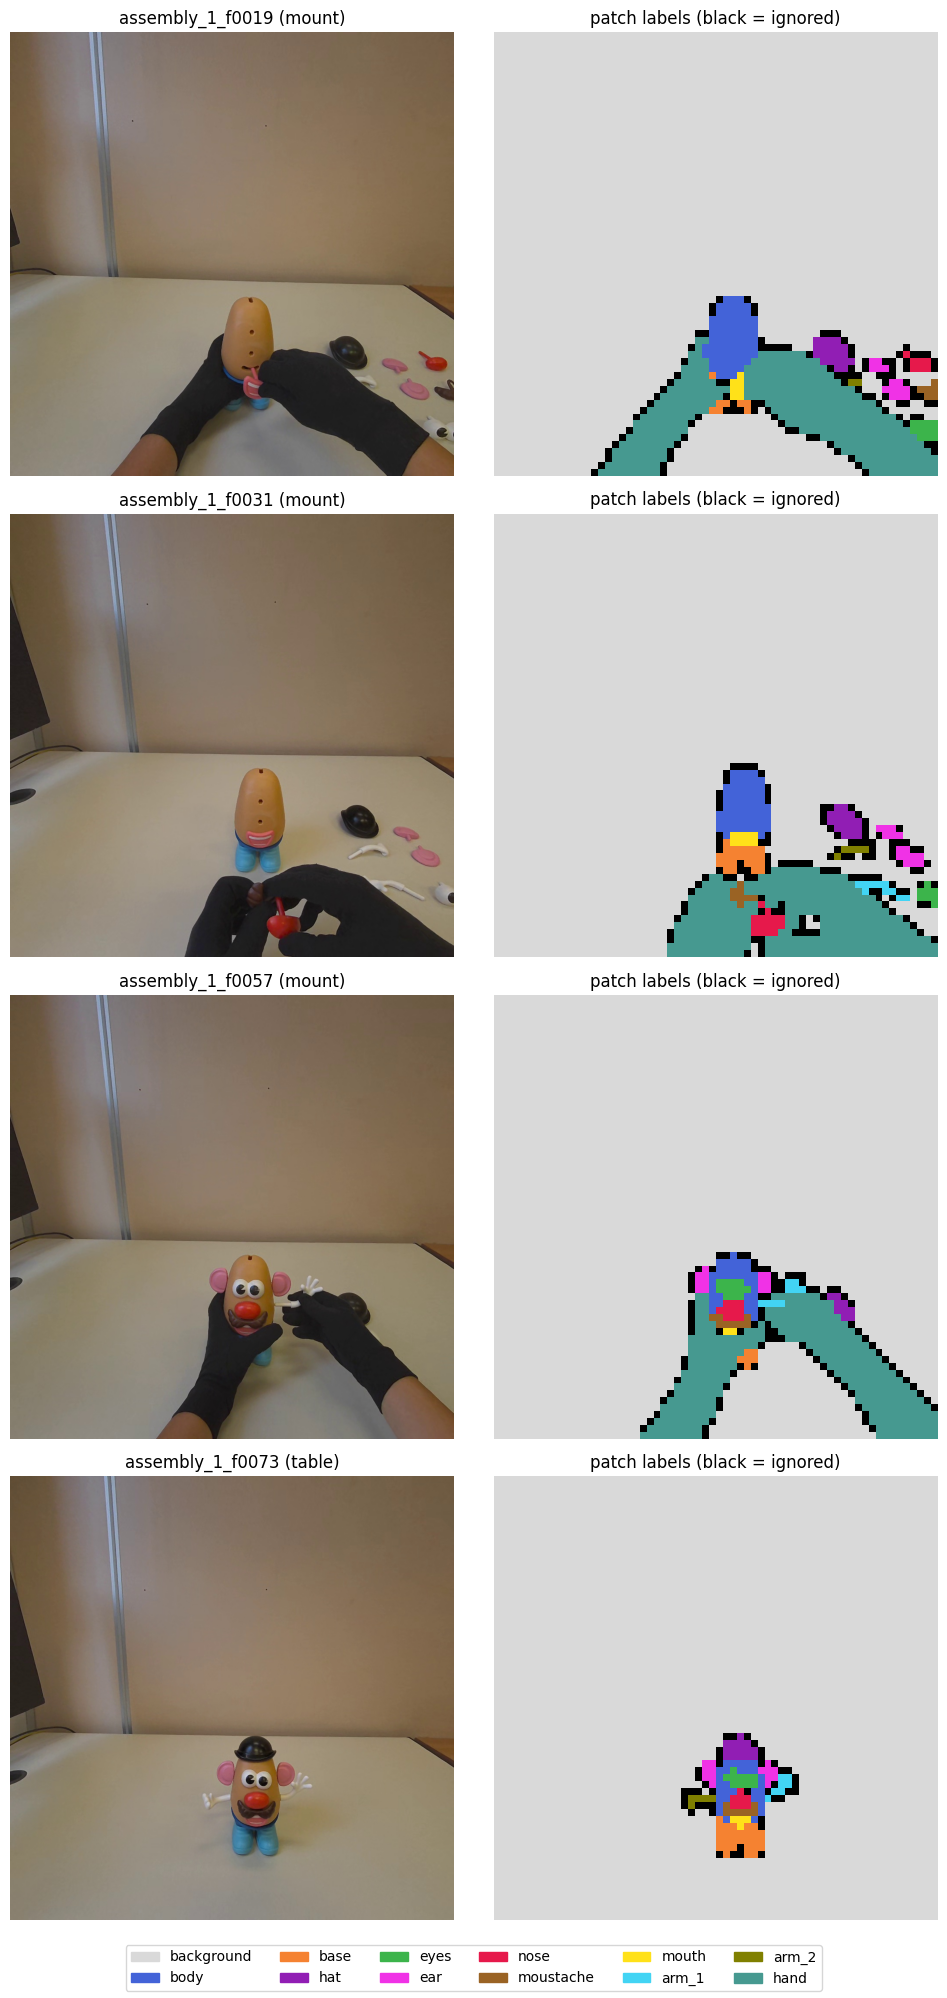

In [12]:
# 4.4 Visual check of the ground truth on four frames chosen before looking: the mouth at its slot between the hands (f0019),
# the nose threaded into the moustache in hand (f0031), arm_1 grazing the body (f0057), the corrected v1-baseline annotation (f0073)
CHECK_FRAMES = ["assembly_1_f0019", "assembly_1_f0031", "assembly_1_f0057", "assembly_1_f0073"]
by_name = {item["frame"]: item for item in TEST_FRAMES}
fig, axes = plt.subplots(len(CHECK_FRAMES), 2, figsize=(10, 5 * len(CHECK_FRAMES)))
present = set()
for row, name in zip(axes, CHECK_FRAMES):
    item = by_name[name]
    row[0].imshow(Image.open(item["image_path"]))
    row[0].set_title(f"{name} ({item['moment']})")
    row[1].imshow(label_grid_to_rgb(item["gt"]), interpolation="nearest")
    row[1].set_title("patch labels (black = ignored)")
    present |= {CLASS_NAMES[i] for i in np.unique(item["gt"]) if i != IGNORE_ID}
    for ax in row:
        ax.axis("off")
handles = [mpatches.Patch(color=CLASS_COLORS[name], label=name) for name in CLASS_NAMES if name in present]
fig.legend(handles=handles, loc="lower center", ncol=6)
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.show()

Observation 4.4: In the four frames the labels follow the rule of rasterize_annotation, the smaller polygon wins. In f0019 the mouth at its slot keeps its class over the body, and the hands around it stay hand. In f0031 the nose and the moustache joined in hand stay separate from the hands that hold them. In f0057, after the correction, the eyes, the nose and the mouth keep their class over the body, and arm_1 touching the body is labelled arm_1. In f0073 the base is labelled base, and the whole figure, seen from farther away, covers few patches per piece.

Borders between classes are ignored (black), as the labelling rule requires.

------------------------------------------------------------------------------------------------------------------------------------------

References Section 4:

src/perception/labels.py, check_annotation, rasterize_annotation and patch_label_grid: the checks of the annotation files and the labelling rule of the pipeline (Section 5).

Russell et al. 2008, LabelMe, Sect. 3.3: overlapping polygons; an object completely contained in another one is on top.

Everingham et al. 2010, PASCAL VOC, Sect. 3.6.1 and 4.2.1: a void border around each object, excluded from the evaluation.

Support-set study on V2, Sections 3.2-3.4: the same checks and counts on the validation frames.

------------------------------------------------------------------------------------------------------------------------------------------

## Section 5 - Measurement plan

This section fixes what is measured on the test frames and how it is reported, before any prediction on assembly_1. It is committed before Sections 6 and 7 are written and run. Nothing in it depends on a result, and no result will change the method, the support set, the frames or the annotations.

Main measure. The mIoU over the 10 pieces on all 31 frames, as in validation. For each piece, true positives, false positives and false negatives are summed over the frames before dividing (frame_miou). arm_1 and arm_2 are kept separate, since mounting one in the place of the other is an error Phase 2 must detect. Hand and background are classified but do not enter the mean. No class is excluded in any frame. The validation value is 0.779.

Descriptive measures. The mIoU of each moment: 9 table, 11 pick and 11 mount frames. The mIoU with the arms merged, where a patch of one arm predicted as the other counts as correct (merge_arms). The IoU of each piece over all frames. For each piece, the share of its patches predicted as each other class, from the confusion matrix summed over the frames, to describe the errors. The overlays of the four frames of Section 4.4 are shown, and those of all 31 frames are saved in outputs/phase_1_test; they are for description and are never used to choose anything.

Uncertainty. The bootstrap of the validation set is used unchanged (support-set study on V2, Section 1 and cell 8.3), with 1000 resamples, seed 0, and the 95% percentile interval, which drops the lowest and the highest 2.5% of the resampled values (Koehn 2004, Sect. 5). Frames close in time are not independent, and the bootstrap of single frames would give intervals that are too narrow (Künsch 1989, Sect. 1). Over all 31 frames in time order, the resamples are therefore made of overlapping blocks of 3 consecutive frames (Künsch 1989, Sect. 2.3): 11 blocks drawn among the 29 possible starts, joined and cut to 31 frames. This applies to the main measure, to the mIoU with the arms merged and to the IoU of each piece. Within a single moment the frames come from different pieces, far apart in time, and are resampled one by one. In validation the interval was on the difference between two support sets; here it is on the value of the fixed method.

Comparison with validation. The test values are reported next to those of validation: mIoU 0.779; table 0.818, pick 0.777 and mount 0.731; arms merged 0.836; and the IoU of each piece of the support-set study on V2 (Section 9.2, current support set). The comparison is descriptive. The two sets have different frames, and the validation values are optimistic, since they were used to choose the method (Cawley and Talbot 2010, Sect. 5). No statistical test is made between them; whether a validation value falls inside the test interval is described, not used to decide anything.

Expectations, written as hypotheses before the run, from the known limits of the method. The test values are lower than those of validation. arm_2 has the lowest IoU of the pieces, and arm_1 and arm_2 are confused, so the gap between the mIoU with the arms merged and the mIoU over the 10 pieces is at least as large as in validation (0.057). The mouth is partly taken for the nose. An arm just picked (f0055, f0060) is partly missed. The small pieces of f0073, where the figure is seen from farther away, are partly lost. These hypotheses are checked in Section 8, for description only.

Single execution. Section 7 is run once, on the committed notebook. The run counts as done as soon as any metric is displayed. If it stops earlier for a technical reason, such as memory or power, it is restarted without changes and the stop is reported. After the metrics are shown, no code, setting, frame or annotation is changed. If an error in the evaluation code is found after the run, it is corrected, both values are reported and the correction is explained. The predictions, labels and similarities of every frame, are saved in outputs/phase_1_test, so that Section 8 and Phase 2 read them and never run the test again.

What is not done. No other frame of assembly_1 is evaluated quantitatively, and no subset of frames or pieces is chosen after the results are seen.

------------------------------------------------------------------------------------------------------------------------------------------

References Section 5:

Künsch 1989, Sect. 1: the bootstrap assumes independent observations, and gives incorrect answers if dependence is neglected. Sect. 2.3: the resamples are made of blocks of consecutive observations, drawn at random with replacement.

Koehn 2004, Sect. 5: bootstrap resampling of the test set; dropping the top and the bottom 2.5% of the resampled scores gives the 95% confidence interval.

Cawley and Talbot 2010, Sect. 5: a performance estimate on data used for selection is optimistically biased.

Support-set study on V2, Section 1 and cell 8.3: the block bootstrap used in validation. Section 9.2: the IoU of each piece in validation, current support set.

Pipeline (phase_1_perception.ipynb), regression check at v1.9-pipeline: mIoU 0.779; table 0.818, pick 0.777, mount 0.731; arms merged 0.836.

------------------------------------------------------------------------------------------------------------------------------------------

## Section 6 - Prototypes

This section loads the V2 prototypes saved by the pipeline (Section 6.4) and checks them, without running any prediction.

The checks compare the metadata saved with the prototypes against the settings of this notebook: the class order, the background margin, the labelling rule, the model and the patch size. They also check that every prototype is a unit vector with a class, that every class has prototypes, and that no reference frame comes from assembly_1 or assembly_2, so the test frames never contributed to the prototypes.

The file is in outputs/, which is not tracked by git. Its SHA-256 fingerprint is printed, so the notebook records which file was used.

In [13]:
# 6.1 Load the saved V2 prototypes and check them against the settings of this notebook
saved = load_patch_prototypes(PROTOTYPES_PATH)
meta, vectors, owners = saved["metadata"], saved["prototypes"], saved["owners"]
reference_sequences = {sequence_of(ref["frame"]) for ref in meta["reference_frames"]}

checks = {
    "class names in the order of CLASS_NAMES": saved["class_names"] == CLASS_NAMES,
    "margin = MARGIN": meta["margin"] == MARGIN,
    "min_label_coverage = MIN_LABEL_COVERAGE": meta["min_label_coverage"] == MIN_LABEL_COVERAGE,
    "model = MODEL_DIR": meta["model"] == MODEL_DIR.name,
    "patch size = PATCH_SIZE": meta["patch_size"] == PATCH_SIZE,
    "feature dimension = width of the vectors": meta["feature_dim"] == vectors.shape[1],
    "one class per prototype": len(owners) == len(vectors),
    "unit vectors (tolerance 1e-4)": bool(np.allclose(np.linalg.norm(vectors, axis=1), 1.0, atol=1e-4)),
    "every class has prototypes": set(np.unique(owners).tolist()) == set(range(len(CLASS_NAMES))),
    "no reference frame from assembly_1 or assembly_2": not (reference_sequences & {"assembly_1", "assembly_2"}),
}
display(pd.Series(checks, name="passed").to_frame())
assert all(checks.values()), "The saved prototypes do not match the settings of this notebook"

fingerprint = hashlib.sha256(PROTOTYPES_PATH.read_bytes()).hexdigest()[:12]
print(f"File: {PROTOTYPES_PATH.name}, {PROTOTYPES_PATH.stat().st_size / 2**20:.0f} MB, SHA-256 {fingerprint}, created {meta['created']}")
print(f"Method: {meta['method']}")
print(f"{len(vectors)} prototypes of dimension {vectors.shape[1]}, from {len(meta['reference_frames'])} reference frames")

display(pd.DataFrame(meta["reference_frames"]).set_index("frame")[["role", "annotation"]])
counts = pd.Series(np.bincount(owners, minlength=len(CLASS_NAMES)), index=CLASS_NAMES, name="prototypes")
display(counts.to_frame().T)

# Prototypes sorted by class, as class_similarities_gpu requires (Section 7); sorting does not change the maxima per class
PROTOTYPES_SORTED = sort_by_class(vectors, owners)

,passed
class names in the order of CLASS_NAMES,True
margin = MARGIN,True
min_label_coverage = MIN_LABEL_COVERAGE,True
model = MODEL_DIR,True
patch size = PATCH_SIZE,True
feature dimension = width of the vectors,True
one class per prototype,True
unit vectors (tolerance 1e-4),True
every class has prototypes,True
no reference frame from assembly_1 or assembly_2,True


File: patch_prototypes.npz, 172 MB, SHA-256 ab0f13579f17, created 2026-10-21 19:04
Method: V2: every labelled reference patch is a prototype; nearest neighbour by cosine similarity
39125 prototypes of dimension 1152, from 10 reference frames


,role,annotation
frame,,
5_assembled_f0002,assembled,data/extracted_frames/5_assembled_f0002.json
caos_f0149,partially assembled,data/extracted_frames/caos_f0149.json
5_assembled_f0019,"assembled, 3/4 view",data/extracted_frames/5_assembled_f0019.json
3_disassembled_ordered_f0001,disassembled,data/extracted_frames/3_disassembled_ordered_f...
2_disassembled_caos_f0016,"disassembled, top-down view",data/extracted_frames/2_disassembled_caos_f001...
Take_3_1_Base_f0099,"base only, upright",data/extracted_frames/Take_3_1_Base_f0099.json
Take_3_1_Base_f0131,"base only, lying",data/extracted_frames/Take_3_1_Base_f0131.json
caos_f0211,hands,data/annotation_versions/margin_study/caos_f02...
4_partially_assembled_f0002,"body on base, face incomplete; mouth loose at 3/4",data/extracted_frames/4_partially_assembled_f0...


,background,body,base,hat,eyes,ear,nose,moustache,mouth,arm_1,arm_2,hand
prototypes,37864,302,201,52,32,52,29,35,28,33,15,482


------------------------------------------------------------------------------------------------------------------------------------------

References Section 6:

Pipeline (phase_1_perception.ipynb), Section 6.4: the V2 prototypes saved with the class of each one and their metadata, then reloaded and compared.

src/perception/prototypes.py, load_patch_prototypes and sort_by_class: loading the file and ordering the prototypes by class for the GPU.

------------------------------------------------------------------------------------------------------------------------------------------